# End-to-End Credit Card Fraud Detection

This notebook analyzes the locally supplied ULB / Worldline benchmark data, audits and cleans an analysis copy, performs exploratory analysis, and compares leakage-safe classifiers. All dataset-specific findings below are computed from `creditcard.csv` when the notebook runs.

**Scope:** demonstrate a reproducible imbalanced-classification workflow, not establish production banking effectiveness. The dataset contains anonymized PCA features and elapsed time without calendar reference information.

## 1. Objective, source, and limitations

The task is to rank transactions for investigation while respecting the severe class imbalance. The commonly documented dataset reference is [MLG-ULB Credit Card Fraud Detection on Kaggle](https://www.kaggle.com/datasets/mlg-ulb/creditcardfraud). No source documentation or license accompanied the local CSV, so provenance beyond the standard benchmark description and redistribution permission cannot be verified here. The raw CSV is kept in place and is not copied into `data/raw/` or redistributed.

`Time` is elapsed seconds, not wall-clock time. `V1`–`V28` are anonymized transformed features, and have no defensible direct business interpretation. Results on this historical benchmark do not establish performance on current transactions or in live banking operations.

## 2. Imports and configuration

In [1]:
from pathlib import Path
import json
import sys
import platform

import joblib
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
import sklearn
from IPython.display import Markdown, display
from sklearn.dummy import DummyClassifier
from sklearn.inspection import permutation_importance
from sklearn.metrics import (
    average_precision_score, classification_report, confusion_matrix,
    precision_recall_curve, roc_curve, roc_auc_score,
)

PROJECT_ROOT = Path.cwd()
if not (PROJECT_ROOT / "creditcard.csv").is_file() and (PROJECT_ROOT.parent / "creditcard.csv").is_file():
    PROJECT_ROOT = PROJECT_ROOT.parent
DATA_PATH = PROJECT_ROOT / "creditcard.csv"
REPORTS_DIR = PROJECT_ROOT / "reports"
PLOTS_DIR = PROJECT_ROOT / "plots"
MODELS_DIR = PROJECT_ROOT / "models"
for directory in (REPORTS_DIR, PLOTS_DIR, MODELS_DIR):
    directory.mkdir(parents=True, exist_ok=True)
sys.path.insert(0, str(PROJECT_ROOT / "src"))

from data_cleaning import clean_dataset
from data_validation import build_quality_audit, validate_schema
from eda import amount_summary, pca_feature_effects, time_bin_summary
from evaluate import select_f2_threshold, test_metrics, threshold_metrics
from train import (
    FEATURE_COLUMNS, RANDOM_SEED, build_models, chronological_split, fit_models,
)

sns.set_theme(style="whitegrid")
pd.set_option("display.max_columns", 40)
pd.set_option("display.width", 140)
print({"python": platform.python_version(), "pandas": pd.__version__,
       "numpy": np.__version__, "scikit_learn": sklearn.__version__,
       "random_seed": RANDOM_SEED, "dataset": str(DATA_PATH)})

{'python': '3.13.9', 'pandas': '2.3.3', 'numpy': '2.3.5', 'scikit_learn': '1.7.2', 'random_seed': 42, 'dataset': 'C:\\Users\\SRIHITHA VSS\\Downloads\\credit-card-fraud-detection\\creditcard.csv'}


## 3. Load the data and verify its schema

The source file is read without modifying it. The schema check is intentionally strict; an unexpected dataset variant stops execution rather than silently changing the analysis.

In [2]:
if not DATA_PATH.is_file():
    raise FileNotFoundError(f"Expected the downloaded dataset at {DATA_PATH}")
raw = pd.read_csv(DATA_PATH)
validate_schema(raw)
print(f"Shape: {raw.shape[0]:,} rows × {raw.shape[1]} columns")
print(f"File size: {DATA_PATH.stat().st_size / (1024 ** 2):.2f} MiB")
print("Column meanings: Time = elapsed seconds; V1–V28 = anonymized transformed features; Amount = transaction amount; Class = 1 fraud, 0 legitimate.")
display(pd.DataFrame({"dtype": raw.dtypes.astype(str), "unique_values": raw.nunique(),
                      "missing": raw.isna().sum()}))
display(raw.head())
display(raw.tail())
display(raw.sample(min(5, len(raw)), random_state=RANDOM_SEED))
display(raw.describe().T)
display(pd.DataFrame({"count": raw["Class"].value_counts().sort_index(),
                      "percentage": raw["Class"].value_counts(normalize=True).sort_index() * 100}))
print(f"Memory usage: {raw.memory_usage(deep=True).sum() / (1024 ** 2):.2f} MiB")

Shape: 284,807 rows × 31 columns
File size: 143.84 MiB
Column meanings: Time = elapsed seconds; V1–V28 = anonymized transformed features; Amount = transaction amount; Class = 1 fraud, 0 legitimate.


,dtype,unique_values,missing
Time,float64,124592,0
V1,float64,275663,0
V2,float64,275663,0
V3,float64,275663,0
V4,float64,275663,0
V5,float64,275663,0
V6,float64,275663,0
V7,float64,275663,0
V8,float64,275663,0
V9,float64,275663,0


,Time,V1,V2,V3,V4,V5,V6,V7,V8,V9,V10,V11,V12,V13,V14,V15,V16,V17,V18,V19,V20,V21,V22,V23,V24,V25,V26,V27,V28,Amount,Class
0,0.0,-1.359807,-0.072781,2.536347,1.378155,-0.338321,0.462388,0.239599,0.098698,0.363787,0.090794,-0.551600,-0.617801,-0.991390,-0.311169,1.468177,-0.470401,0.207971,0.025791,0.403993,0.251412,-0.018307,0.277838,-0.110474,0.066928,0.128539,-0.189115,0.133558,-0.021053,149.62,0
1,0.0,1.191857,0.266151,0.166480,0.448154,0.060018,-0.082361,-0.078803,0.085102,-0.255425,-0.166974,1.612727,1.065235,0.489095,-0.143772,0.635558,0.463917,-0.114805,-0.183361,-0.145783,-0.069083,-0.225775,-0.638672,0.101288,-0.339846,0.167170,0.125895,-0.008983,0.014724,2.69,0
2,1.0,-1.358354,-1.340163,1.773209,0.379780,-0.503198,1.800499,0.791461,0.247676,-1.514654,0.207643,0.624501,0.066084,0.717293,-0.165946,2.345865,-2.890083,1.109969,-0.121359,-2.261857,0.524980,0.247998,0.771679,0.909412,-0.689281,-0.327642,-0.139097,-0.055353,-0.059752,378.66,0
3,1.0,-0.966272,-0.185226,1.792993,-0.863291,-0.010309,1.247203,0.237609,0.377436,-1.387024,-0.054952,-0.226487,0.178228,0.507757,-0.287924,-0.631418,-1.059647,-0.684093,1.965775,-1.232622,-0.208038,-0.108300,0.005274,-0.190321,-1.175575,0.647376,-0.221929,0.062723,0.061458,123.50,0
4,2.0,-1.158233,0.877737,1.548718,0.403034,-0.407193,0.095921,0.592941,-0.270533,0.817739,0.753074,-0.822843,0.538196,1.345852,-1.119670,0.175121,-0.451449,-0.237033,-0.038195,0.803487,0.408542,-0.009431,0.798278,-0.137458,0.141267,-0.206010,0.502292,0.219422,0.215153,69.99,0


,Time,V1,V2,V3,V4,V5,V6,V7,V8,V9,V10,V11,V12,V13,V14,V15,V16,V17,V18,V19,V20,V21,V22,V23,V24,V25,V26,V27,V28,Amount,Class
284802,172786.0,-11.881118,10.071785,-9.834783,-2.066656,-5.364473,-2.606837,-4.918215,7.305334,1.914428,4.356170,-1.593105,2.711941,-0.689256,4.626942,-0.924459,1.107641,1.991691,0.510632,-0.682920,1.475829,0.213454,0.111864,1.014480,-0.509348,1.436807,0.250034,0.943651,0.823731,0.77,0
284803,172787.0,-0.732789,-0.055080,2.035030,-0.738589,0.868229,1.058415,0.024330,0.294869,0.584800,-0.975926,-0.150189,0.915802,1.214756,-0.675143,1.164931,-0.711757,-0.025693,-1.221179,-1.545556,0.059616,0.214205,0.924384,0.012463,-1.016226,-0.606624,-0.395255,0.068472,-0.053527,24.79,0
284804,172788.0,1.919565,-0.301254,-3.249640,-0.557828,2.630515,3.031260,-0.296827,0.708417,0.432454,-0.484782,0.411614,0.063119,-0.183699,-0.510602,1.329284,0.140716,0.313502,0.395652,-0.577252,0.001396,0.232045,0.578229,-0.037501,0.640134,0.265745,-0.087371,0.004455,-0.026561,67.88,0
284805,172788.0,-0.240440,0.530483,0.702510,0.689799,-0.377961,0.623708,-0.686180,0.679145,0.392087,-0.399126,-1.933849,-0.962886,-1.042082,0.449624,1.962563,-0.608577,0.509928,1.113981,2.897849,0.127434,0.265245,0.800049,-0.163298,0.123205,-0.569159,0.546668,0.108821,0.104533,10.00,0
284806,172792.0,-0.533413,-0.189733,0.703337,-0.506271,-0.012546,-0.649617,1.577006,-0.414650,0.486180,-0.915427,-1.040458,-0.031513,-0.188093,-0.084316,0.041333,-0.302620,-0.660377,0.167430,-0.256117,0.382948,0.261057,0.643078,0.376777,0.008797,-0.473649,-0.818267,-0.002415,0.013649,217.00,0


,Time,V1,V2,V3,V4,V5,V6,V7,V8,V9,V10,V11,V12,V13,V14,V15,V16,V17,V18,V19,V20,V21,V22,V23,V24,V25,V26,V27,V28,Amount,Class
43428,41505.0,-16.526507,8.584972,-18.649853,9.505594,-13.793819,-2.832404,-16.701694,7.517344,-8.507059,-14.110184,5.299236,-10.834006,1.671120,-9.373859,0.360806,-9.899247,-19.236292,-8.398552,3.101735,-1.514923,1.190739,-1.127670,-2.358579,0.673461,-1.413700,-0.462762,-2.018575,-1.042804,364.19,1
49906,44261.0,0.339812,-2.743745,-0.134070,-1.385729,-1.451413,1.015887,-0.524379,0.224060,0.899746,-0.565012,-0.087670,0.979427,0.076883,-0.217884,-0.136830,-2.142892,0.126956,1.752662,0.432546,0.506044,-0.213436,-0.942525,-0.526819,-1.156992,0.311211,-0.746647,0.040996,0.102038,520.12,0
29474,35484.0,1.399590,-0.590701,0.168619,-1.029950,-0.539806,0.040444,-0.712567,0.002299,-0.971747,0.756801,0.543827,0.112453,1.075384,-0.245772,0.180483,1.769860,-0.533172,-0.533300,1.192245,0.212877,0.102398,0.168269,-0.166639,-0.810250,0.505083,-0.232340,0.011409,0.004634,31.00,0
276481,167123.0,-0.432071,1.647895,-1.669361,-0.349504,0.785785,-0.630647,0.276990,0.586025,-0.484715,-1.376648,-1.328335,0.223621,1.132627,-0.550875,0.616568,0.497974,0.502195,0.981343,0.101264,-0.244633,0.358932,0.873663,-0.178642,-0.017171,-0.207392,-0.157756,-0.237386,0.001934,1.50,0
278846,168473.0,2.014160,-0.137394,-1.015839,0.327269,-0.182179,-0.956571,0.043241,-0.160746,0.363241,0.259452,0.942162,0.850038,-0.616166,0.592634,-0.603845,0.091077,-0.471867,-0.333816,0.404711,-0.255293,-0.238644,-0.616400,0.347045,0.061561,-0.360196,0.174730,-0.078043,-0.070571,0.89,0


,count,mean,std,min,25%,50%,75%,max
Time,284807.0,9.481386e+04,47488.145955,0.000000,54201.500000,84692.000000,139320.500000,172792.000000
V1,284807.0,1.175161e-15,1.958696,-56.407510,-0.920373,0.018109,1.315642,2.454930
V2,284807.0,3.384974e-16,1.651309,-72.715728,-0.598550,0.065486,0.803724,22.057729
V3,284807.0,-1.379537e-15,1.516255,-48.325589,-0.890365,0.179846,1.027196,9.382558
V4,284807.0,2.094852e-15,1.415869,-5.683171,-0.848640,-0.019847,0.743341,16.875344
V5,284807.0,1.021879e-15,1.380247,-113.743307,-0.691597,-0.054336,0.611926,34.801666
V6,284807.0,1.494498e-15,1.332271,-26.160506,-0.768296,-0.274187,0.398565,73.301626
V7,284807.0,-5.620335e-16,1.237094,-43.557242,-0.554076,0.040103,0.570436,120.589494
V8,284807.0,1.149614e-16,1.194353,-73.216718,-0.208630,0.022358,0.327346,20.007208
V9,284807.0,-2.414189e-15,1.098632,-13.434066,-0.643098,-0.051429,0.597139,15.594995


,count,percentage
Class,,
0,284315,99.827251
1,492,0.172749


Memory usage: 67.36 MiB


## 4. Data-quality audit

Extremes are treated as observations to investigate, not errors by default. The table records actual values and whether any column-level action is justified.

In [3]:
audit = build_quality_audit(raw)
audit.to_csv(REPORTS_DIR / "data_quality_audit.csv", index=False)
display(audit)
dupe_mask = raw.duplicated(keep="first")
duplicate_counts_by_class = raw.loc[dupe_mask, "Class"].value_counts().sort_index()
display(pd.DataFrame({"duplicate_rows": duplicate_counts_by_class}))
display(Markdown(
    f"**Audit interpretation.** The file contains **{len(raw):,} rows** and "
    f"**{int(raw.isna().sum().sum()):,} missing values**. Exact duplicate rows "
    f"number **{int(dupe_mask.sum()):,}** (" + ", ".join(
        f"class {int(k)}: {int(v)}" for k, v in duplicate_counts_by_class.items()
    ) + "). The features are numeric and the target encoding is binary. Duplicate "
    "records can appear on opposite sides of a row-based time split; exact duplicates "
    "are therefore removed from the analysis copy before splitting. Non-duplicate "
    "outliers are retained unless a validity check indicates corruption."
))

,column,data_type,missing_count,missing_percentage,unique_count,minimum,maximum,duplicate_or_anomaly_notes,action_taken,reason
0,Time,float64,0,0.0,124592,0.000000,172792.000000,none detected,none,Values retained; no column-level cleaning indi...
1,V1,float64,0,0.0,275663,-56.407510,2.454930,none detected,none,Values retained; no column-level cleaning indi...
2,V2,float64,0,0.0,275663,-72.715728,22.057729,none detected,none,Values retained; no column-level cleaning indi...
3,V3,float64,0,0.0,275663,-48.325589,9.382558,none detected,none,Values retained; no column-level cleaning indi...
4,V4,float64,0,0.0,275663,-5.683171,16.875344,none detected,none,Values retained; no column-level cleaning indi...
5,V5,float64,0,0.0,275663,-113.743307,34.801666,none detected,none,Values retained; no column-level cleaning indi...
6,V6,float64,0,0.0,275663,-26.160506,73.301626,none detected,none,Values retained; no column-level cleaning indi...
7,V7,float64,0,0.0,275663,-43.557242,120.589494,none detected,none,Values retained; no column-level cleaning indi...
8,V8,float64,0,0.0,275663,-73.216718,20.007208,none detected,none,Values retained; no column-level cleaning indi...
9,V9,float64,0,0.0,275663,-13.434066,15.594995,none detected,none,Values retained; no column-level cleaning indi...


,duplicate_rows
Class,
0,1062
1,19


**Audit interpretation.** The file contains **284,807 rows** and **0 missing values**. Exact duplicate rows number **1,081** (class 0: 1062, class 1: 19). The features are numeric and the target encoding is binary. Duplicate records can appear on opposite sides of a row-based time split; exact duplicates are therefore removed from the analysis copy before splitting. Non-duplicate outliers are retained unless a validity check indicates corruption.

## 5. Cleaning and post-cleaning validation

Only exact duplicate rows are removed. No missing-value imputation, outlier trimming, scaling, or target editing is performed here. Model-specific scaling is later fitted inside the training pipeline.

In [4]:
data, cleaning_summary = clean_dataset(raw)
display(pd.Series(cleaning_summary, name="value").to_frame())
display(pd.DataFrame({"before_rows": [len(raw)], "after_rows": [len(data)],
                      "before_missing": [int(raw.isna().sum().sum())],
                      "after_missing": [int(data.isna().sum().sum())],
                      "after_duplicates": [int(data.duplicated().sum())]}))
print("Final dtypes:", data.dtypes.astype(str).to_dict())
assert data["Class"].isin([0, 1]).all() and data["Time"].is_monotonic_increasing
display(Markdown(
    f"**Cleaning interpretation.** The analysis set contains {len(data):,} rows after "
    f"removing {cleaning_summary['records_removed']:,} exact duplicates; the raw "
    f"CSV remains unchanged. Missing and non-finite values after cleaning are "
    f"{int(data.isna().sum().sum())} and "
    f"{int((~np.isfinite(data.select_dtypes(include='number').to_numpy())).sum())}, "
    "respectively. No imputation or outlier removal was warranted by these checks."
))

,value
original_rows,284807
duplicate_rows_identified,1081
records_removed,1081
final_rows,283726
missing_values_before,0
missing_values_after,0
non_finite_values,0
cleaning_decision,"Removed exact duplicate rows, keeping the firs..."


,before_rows,after_rows,before_missing,after_missing,after_duplicates
0,284807,283726,0,0,0


Final dtypes: {'Time': 'float64', 'V1': 'float64', 'V2': 'float64', 'V3': 'float64', 'V4': 'float64', 'V5': 'float64', 'V6': 'float64', 'V7': 'float64', 'V8': 'float64', 'V9': 'float64', 'V10': 'float64', 'V11': 'float64', 'V12': 'float64', 'V13': 'float64', 'V14': 'float64', 'V15': 'float64', 'V16': 'float64', 'V17': 'float64', 'V18': 'float64', 'V19': 'float64', 'V20': 'float64', 'V21': 'float64', 'V22': 'float64', 'V23': 'float64', 'V24': 'float64', 'V25': 'float64', 'V26': 'float64', 'V27': 'float64', 'V28': 'float64', 'Amount': 'float64', 'Class': 'int64'}


**Cleaning interpretation.** The analysis set contains 283,726 rows after removing 1,081 exact duplicates; the raw CSV remains unchanged. Missing and non-finite values after cleaning are 0 and 0, respectively. No imputation or outlier removal was warranted by these checks.

## 6. EDA A — Target class distribution

Precision-recall metrics are central under this level of imbalance. ROC-AUC is useful as a complementary ranking measure but does not describe the false-alert burden at a chosen threshold.

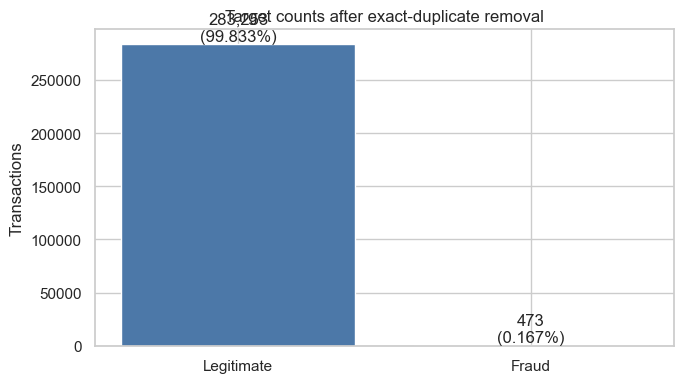

**Interpretation.** After deduplication, 473 of 283,726 transactions are fraud (0.1667%); the fraud-to-legitimate ratio is 1:598.8. A classifier that always predicts legitimate would have 99.8333% accuracy while finding no fraud, so accuracy alone is misleading. Average precision, precision, recall, F-scores, and confusion counts are more informative. This imbalance is not a barrier to training, but it makes split design and threshold choice consequential.

In [5]:
class_counts = data["Class"].value_counts().sort_index()
fraud_count = int(class_counts.loc[1])
raw_fraud_count = int(raw["Class"].sum())
legitimate_count = int(class_counts.loc[0])
fraud_rate = fraud_count / len(data)
fig, ax = plt.subplots(figsize=(7, 4))
bars = ax.bar(["Legitimate", "Fraud"], [legitimate_count, fraud_count], color=["#4C78A8", "#E45756"])
ax.set_ylabel("Transactions")
ax.set_title("Target counts after exact-duplicate removal")
for bar, count in zip(bars, [legitimate_count, fraud_count]):
    ax.text(bar.get_x() + bar.get_width()/2, bar.get_height(), f"{count:,}\n({count/len(data):.3%})", ha="center", va="bottom")
fig.tight_layout()
fig.savefig(PLOTS_DIR / "class_distribution.png", dpi=150)
plt.show()
display(Markdown(
    f"**Interpretation.** After deduplication, {fraud_count:,} of {len(data):,} "
    f"transactions are fraud ({fraud_rate:.4%}); the fraud-to-legitimate ratio is "
    f"1:{legitimate_count/fraud_count:,.1f}. A classifier that always predicts "
    f"legitimate would have {legitimate_count/len(data):.4%} accuracy while finding "
    "no fraud, so accuracy alone is misleading. Average precision, precision, recall, "
    "F-scores, and confusion counts are more informative. This imbalance is not a "
    "barrier to training, but it makes split design and threshold choice consequential."
))

## 7. EDA B — Transaction amount

Amounts are retained even when extreme. A log-transformed view helps show the dense lower range without concealing the long tail; group summaries quantify differences.

,class,class_name,count,mean,median,standard_deviation,q1,q3,p90,p95,p99,maximum
0,0,legitimate,283253,88.414,22.00,250.379,5.67,77.46,203.000,365.00,1018.058,25691.16
1,1,fraud,473,123.872,9.82,260.211,1.00,105.89,348.652,655.82,1364.137,2125.87


C:\Users\SRIHITHA VSS\AppData\Local\Temp\ipykernel_17800\2298100833.py:9: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(data=data, x="Class", y="Amount", showfliers=False, ax=axes[1], palette={"0": "#4C78A8", "1": "#E45756"})


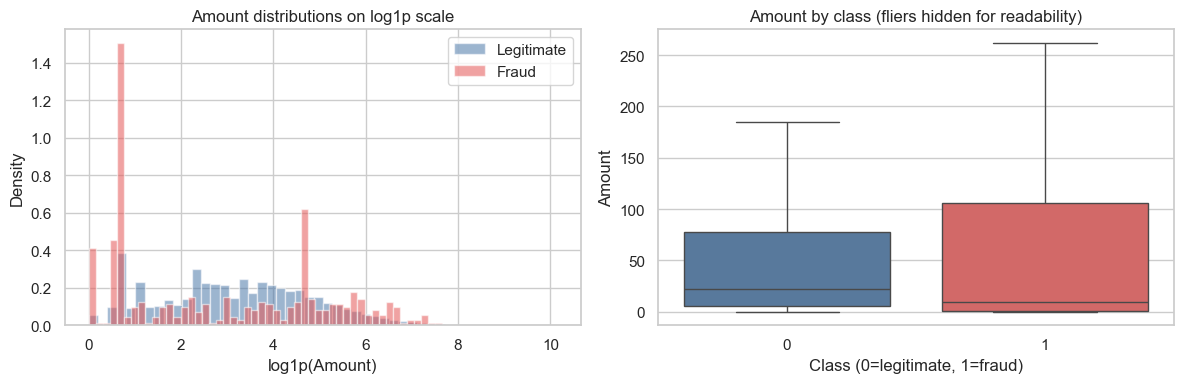

**Interpretation.** Legitimate transactions have mean/median amount 88.41/22.00; fraud transactions have 123.87/9.82. The fraud mean is above its median, indicating a right tail; the groups overlap substantially in the displayed ranges. The observed maxima are 25691.16 (legitimate) and 2125.87 (fraud). This descriptive difference does not establish predictive performance, and a single amount cutoff is not justified by these overlapping distributions. The fraud group is comparatively small, so its tail summaries are uncertain.

In [6]:
amount_stats = amount_summary(data)
display(amount_stats.round(3))
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
for label, name, color in [(0, "Legitimate", "#4C78A8"), (1, "Fraud", "#E45756")]:
    values = np.log1p(data.loc[data.Class == label, "Amount"])
    axes[0].hist(values, bins=50, alpha=0.55, density=True, label=name, color=color)
axes[0].set(title="Amount distributions on log1p scale", xlabel="log1p(Amount)", ylabel="Density")
axes[0].legend()
sns.boxplot(data=data, x="Class", y="Amount", showfliers=False, ax=axes[1], palette={"0": "#4C78A8", "1": "#E45756"})
axes[1].set(title="Amount by class (fliers hidden for readability)", xlabel="Class (0=legitimate, 1=fraud)", ylabel="Amount")
fig.tight_layout()
fig.savefig(PLOTS_DIR / "amount_by_class.png", dpi=150)
plt.show()
leg = amount_stats.loc[amount_stats["class"] == 0].iloc[0]
fraud = amount_stats.loc[amount_stats["class"] == 1].iloc[0]
display(Markdown(
    f"**Interpretation.** Legitimate transactions have mean/median amount "
    f"{leg['mean']:.2f}/{leg['median']:.2f}; fraud transactions have "
    f"{fraud['mean']:.2f}/{fraud['median']:.2f}. The fraud mean is above its median, "
    f"indicating a right tail; the groups overlap substantially in the displayed "
    f"ranges. The observed maxima are {leg['maximum']:.2f} (legitimate) and "
    f"{fraud['maximum']:.2f} (fraud). This descriptive difference does not establish "
    "predictive performance, and a single amount cutoff is not justified by these "
    "overlapping distributions. The fraud group is comparatively small, so its "
    "tail summaries are uncertain."
))

## 8. EDA C — Elapsed transaction time

`Time` is not converted to date, hour, or weekday. Ten equal-width elapsed-time bins show transaction volume and denominators alongside fraud rates.

,count,min,max,mean,median
Class,,,,,
0,283253,0.0,172792.0,94835.058093,84711.0
1,473,406.0,170348.0,80450.513742,73408.0


,time_interval,transaction_count,fraud_count,fraud_rate,time_start_seconds,time_end_seconds
0,"(-172.793, 17279.2]",10468,42,0.004012,-172.793,17279.2
1,"(17279.2, 34558.4]",16889,48,0.002842,17279.200,34558.4
2,"(34558.4, 51837.6]",38374,79,0.002059,34558.400,51837.6
3,"(51837.6, 69116.8]",38392,58,0.001511,51837.600,69116.8
4,"(69116.8, 86396.0]",40111,45,0.001122,69116.800,86396.0
5,"(86396.0, 103675.2]",10097,59,0.005843,86396.000,103675.2
6,"(103675.2, 120954.4]",17115,11,0.000643,103675.200,120954.4
7,"(120954.4, 138233.6]",38846,34,0.000875,120954.400,138233.6
8,"(138233.6, 155512.8]",40605,65,0.001601,138233.600,155512.8
9,"(155512.8, 172792.0]",32829,32,0.000975,155512.800,172792.0


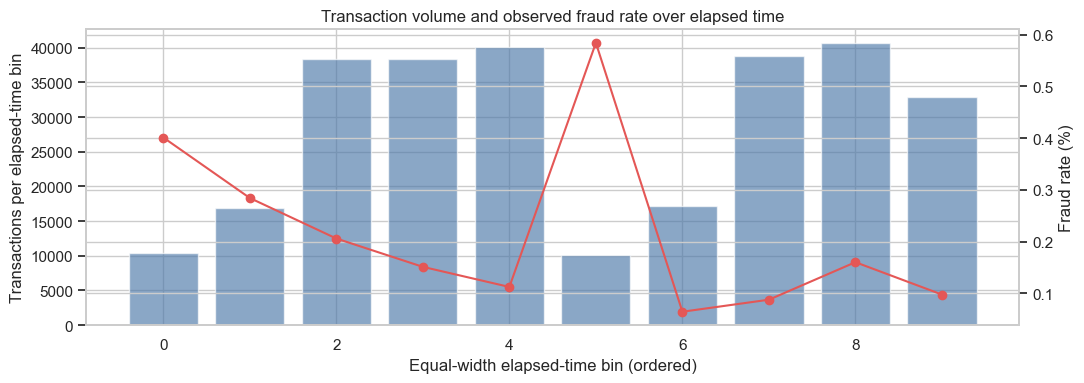

**Interpretation.** Elapsed time spans 0 to 172,792 seconds (48.00 hours of dataset-relative elapsed time), not a documented clock interval. The highest fraud rate among these bins is 0.584% in the bin [86,396, 103,675] seconds, with 10,097 transactions. Rates are based on equal-width time intervals with their plotted denominators, but fraud counts remain sparse. A historical pattern here may reflect temporal drift and does not establish stability; chronological evaluation is therefore included as a useful, still imperfect experiment.

In [7]:
time_table = time_bin_summary(data, bins=10)
time_summary = data.groupby("Class")["Time"].agg(["count", "min", "max", "mean", "median"])
display(time_summary)
display(time_table.round(6))
fig, ax1 = plt.subplots(figsize=(11, 4))
x = np.arange(len(time_table))
ax1.bar(x, time_table.transaction_count, color="#4C78A8", alpha=0.65)
ax1.set_ylabel("Transactions per elapsed-time bin")
ax1.set_xlabel("Equal-width elapsed-time bin (ordered)")
ax2 = ax1.twinx()
ax2.plot(x, time_table.fraud_rate * 100, color="#E45756", marker="o")
ax2.set_ylabel("Fraud rate (%)")
ax1.set_title("Transaction volume and observed fraud rate over elapsed time")
fig.tight_layout()
fig.savefig(PLOTS_DIR / "elapsed_time_patterns.png", dpi=150)
plt.show()
max_bin = time_table.loc[time_table.fraud_rate.idxmax()]
display(Markdown(
    f"**Interpretation.** Elapsed time spans {data.Time.min():,.0f} to "
    f"{data.Time.max():,.0f} seconds ({(data.Time.max()-data.Time.min())/3600:.2f} "
    f"hours of dataset-relative elapsed time), not a documented clock interval. The "
    f"highest fraud rate among these bins is {max_bin.fraud_rate:.3%} in the bin "
    f"[{max_bin.time_start_seconds:,.0f}, {max_bin.time_end_seconds:,.0f}] seconds, "
    f"with {int(max_bin.transaction_count):,} transactions. Rates are based on "
    "equal-width time intervals with their plotted denominators, but fraud counts "
    "remain sparse. A historical pattern here may reflect temporal "
    "drift and does not establish stability; chronological evaluation is therefore "
    "included as a useful, still imperfect experiment."
))

## 9. EDA D — Anonymized PCA features

Effect sizes are descriptive comparisons, not feature selection or proof of future predictive value. The six largest absolute standardized mean differences are shown for readability; the later model is evaluated on all 28 variables.

,feature,legitimate_mean,fraud_mean,legitimate_median,fraud_median,standardized_mean_difference,ks_statistic,absolute_effect
16,V17,0.0110,-6.4633,-0.0651,-5.1576,-8.0924,0.7355,8.0924
13,V14,0.0117,-6.8359,0.0515,-6.5906,-7.5222,0.8377,7.5222
11,V12,0.0095,-6.1033,0.1406,-5.4374,-6.3482,0.7766,6.3482
9,V10,0.0077,-5.4533,-0.0921,-4.4663,-5.1856,0.7970,5.1856
15,V16,0.0078,-4.0010,0.0681,-3.3029,-4.6709,0.6782,4.6709
2,V3,0.0129,-6.7296,0.1822,-4.8754,-4.5453,0.6952,4.5453
6,V7,0.0104,-5.1759,0.0417,-2.9021,-4.2887,0.6516,4.2887
10,V11,-0.0060,3.7163,-0.0344,3.5257,3.6952,0.7474,3.6952
3,V4,-0.0104,4.4726,-0.0245,4.1001,3.1969,0.7607,3.1969
17,V18,0.0051,-2.1571,-0.0014,-1.4179,-2.5965,0.4893,2.5965


C:\Users\SRIHITHA VSS\AppData\Local\Temp\ipykernel_17800\4057209290.py:6: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(data=data, x="Class", y=feature, showfliers=False, ax=ax,


C:\Users\SRIHITHA VSS\AppData\Local\Temp\ipykernel_17800\4057209290.py:6: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(data=data, x="Class", y=feature, showfliers=False, ax=ax,


C:\Users\SRIHITHA VSS\AppData\Local\Temp\ipykernel_17800\4057209290.py:6: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(data=data, x="Class", y=feature, showfliers=False, ax=ax,


C:\Users\SRIHITHA VSS\AppData\Local\Temp\ipykernel_17800\4057209290.py:6: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(data=data, x="Class", y=feature, showfliers=False, ax=ax,


C:\Users\SRIHITHA VSS\AppData\Local\Temp\ipykernel_17800\4057209290.py:6: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(data=data, x="Class", y=feature, showfliers=False, ax=ax,


C:\Users\SRIHITHA VSS\AppData\Local\Temp\ipykernel_17800\4057209290.py:6: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(data=data, x="Class", y=feature, showfliers=False, ax=ax,


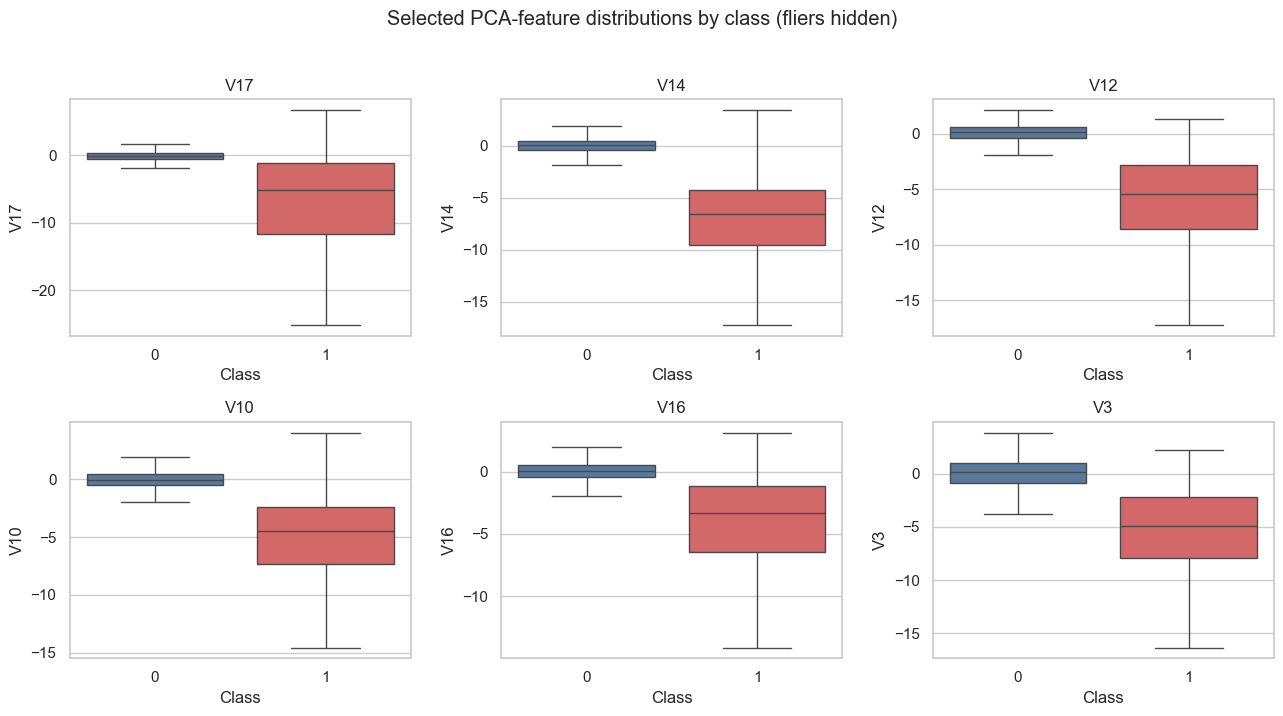

**Interpretation.** The three largest absolute standardized mean differences are V17 (-8.092; KS statistic 0.736); V14 (-7.522; KS statistic 0.838); V12 (-6.348; KS statistic 0.777). These summarize observed separation in this labeled dataset, not causal mechanisms or named banking concepts. The visual comparisons cannot by themselves establish validation-period usefulness; predictive value is assessed later using held-out validation average precision.

In [8]:
feature_effects = pca_feature_effects(data)
display(feature_effects.head(10).round(4))
selected_pca = feature_effects.head(6).feature.tolist()
fig, axes = plt.subplots(2, 3, figsize=(13, 7))
for feature, ax in zip(selected_pca, axes.flat):
    sns.boxplot(data=data, x="Class", y=feature, showfliers=False, ax=ax,
                palette={"0": "#4C78A8", "1": "#E45756"})
    ax.set_title(feature)
    ax.set_xlabel("Class")
fig.suptitle("Selected PCA-feature distributions by class (fliers hidden)", y=1.02)
fig.tight_layout()
fig.savefig(PLOTS_DIR / "selected_pca_distributions.png", dpi=150, bbox_inches="tight")
plt.show()
top_effects = feature_effects.head(3)
display(Markdown(
    "**Interpretation.** The three largest absolute standardized mean differences "
    "are " + "; ".join(
        f"{r.feature} ({r.standardized_mean_difference:.3f}; KS statistic {r.ks_statistic:.3f})"
        for r in top_effects.itertuples()
    ) + ". These summarize observed separation in this labeled dataset, not causal "
    "mechanisms or named banking concepts. The visual comparisons cannot by "
    "themselves establish validation-period usefulness; predictive value is assessed "
    "later using held-out validation average precision."
))

## 10. EDA E — Correlation and relationships

Correlations are linear association summaries. Because the target is rare and binary, its Pearson correlations are not a complete measure of predictive usefulness.

,feature_1,feature_2,correlation
0,V8,V21,0.0189
1,V1,V27,-0.0157
2,V27,V28,-0.0140
3,V7,V10,-0.0136
4,V14,V17,-0.0136
5,V12,V17,-0.0129
6,V9,V10,-0.0126
7,V3,V7,-0.0117


,pearson_correlation_with_Class
V17,-0.3135
V14,-0.2934
V12,-0.2507
V10,-0.2070
V16,-0.1872
V3,-0.1823
V7,-0.1723
V11,0.1491


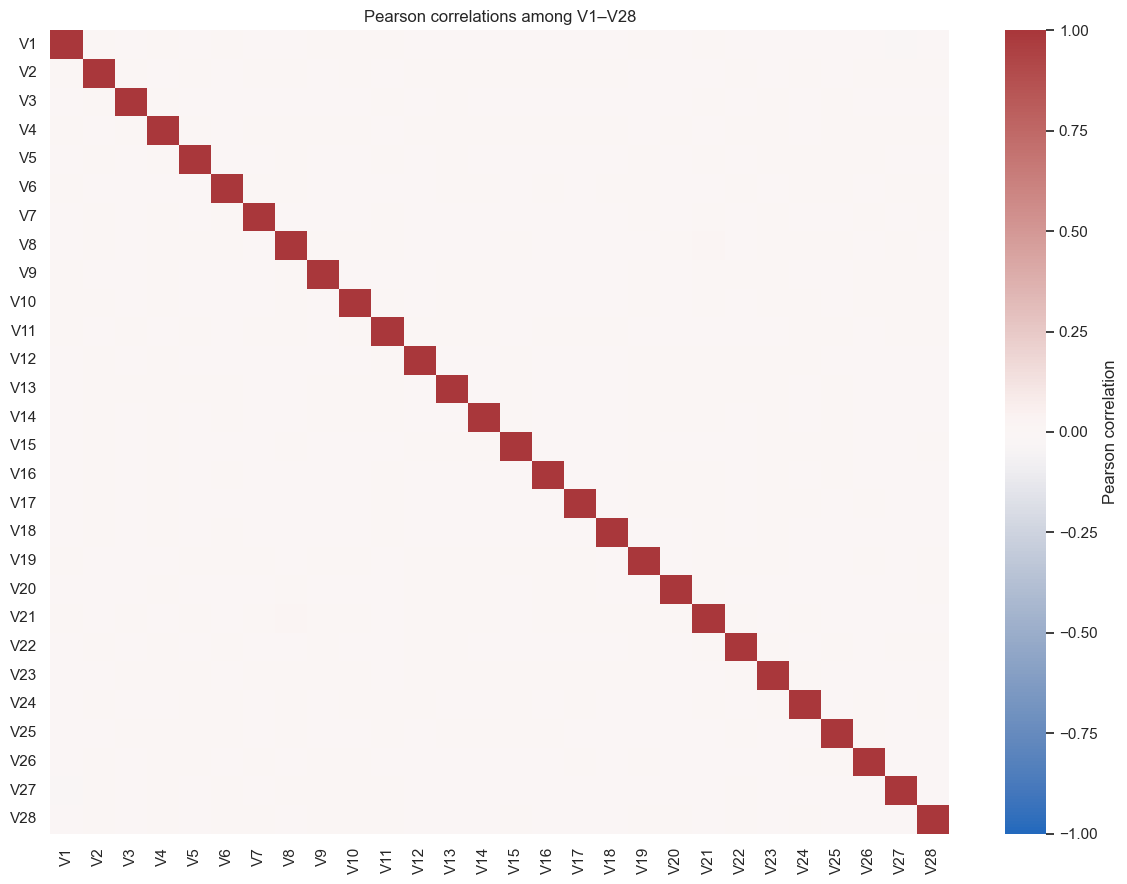

**Interpretation.** The strongest within-PCA feature correlations include V8–V21: 0.019; V1–V27: -0.016; V27–V28: -0.014. Correlated inputs may carry redundant information, but correlation alone does not prove harmful multicollinearity for tree models or imply causation. The largest absolute Pearson associations with the imbalanced binary target are V17 (-0.313) and V14 (-0.293). Low correlation does not rule out nonlinear or interaction-based predictive value.

In [9]:
numeric_corr = data.corr(numeric_only=True)
feature_corr = numeric_corr.loc[[f"V{i}" for i in range(1, 29)], [f"V{i}" for i in range(1, 29)]]
upper = feature_corr.where(np.triu(np.ones(feature_corr.shape), k=1).astype(bool))
strongest_pairs = upper.stack().abs().sort_values(ascending=False).head(8)
corr_pairs = pd.DataFrame([
    {"feature_1": a, "feature_2": b, "correlation": feature_corr.loc[a, b]}
    for a, b in strongest_pairs.index
])
display(corr_pairs.round(4))
target_corr = numeric_corr["Class"].drop("Class").sort_values(key=np.abs, ascending=False).head(8)
display(target_corr.rename("pearson_correlation_with_Class").to_frame().round(4))
fig, ax = plt.subplots(figsize=(12, 9))
sns.heatmap(feature_corr, cmap="vlag", center=0, vmin=-1, vmax=1, ax=ax, cbar_kws={"label": "Pearson correlation"})
ax.set_title("Pearson correlations among V1–V28")
fig.tight_layout()
fig.savefig(PLOTS_DIR / "pca_correlation_heatmap.png", dpi=150)
plt.show()
pair_text = "; ".join(
    f"{r.feature_1}–{r.feature_2}: {r.correlation:.3f}" for r in corr_pairs.head(3).itertuples()
)
display(Markdown(
    f"**Interpretation.** The strongest within-PCA feature correlations include {pair_text}. "
    "Correlated inputs may carry redundant information, but correlation alone does not "
    "prove harmful multicollinearity for tree models or imply causation. The largest "
    f"absolute Pearson associations with the imbalanced binary target are "
    f"{target_corr.index[0]} ({target_corr.iloc[0]:.3f}) and "
    f"{target_corr.index[1]} ({target_corr.iloc[1]:.3f}). Low correlation does not "
    "rule out nonlinear or interaction-based predictive value."
))

## 11. EDA F — Fraud rates across amount and elapsed-time ranges

Rates are displayed with transaction and fraud counts so a high rate in a sparse bin is not mistaken for a stable population estimate. These are descriptive analyses, not causal comparisons.

,amount_bin,transaction_count,fraud_count,fraud_rate
0,"(-0.001, 3.58]",56993,197,0.003457
1,"(3.58, 13.04]",56498,49,0.000867
2,"(13.04, 37.07]",56755,30,0.000529
3,"(37.07, 100.0]",57081,72,0.001261
4,"(100.0, 25691.16]",56399,125,0.002216


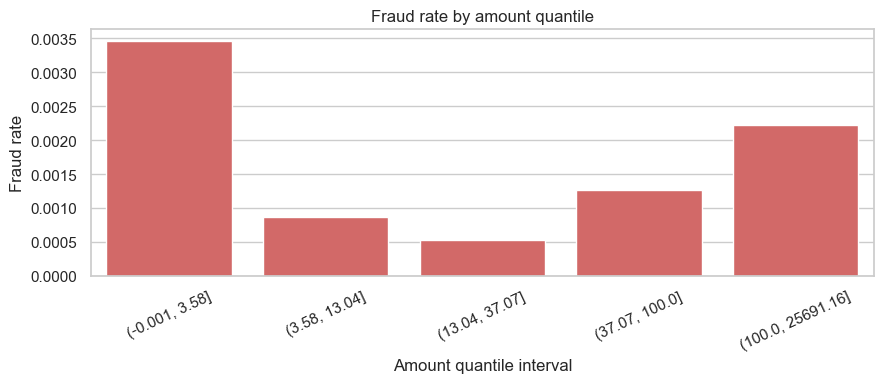

**Interpretation.** Amount quantile rates range from 0.053% to 0.346%; the accompanying counts show the denominator for each interval. Quantile grouping is descriptive and does not define a safe decision cutoff. A model must combine signals and be evaluated against held-out transactions.

,time_start_seconds,time_end_seconds,transaction_count,fraud_count,fraud_rate
0,-172.793,17279.2,10468,42,0.004012
1,17279.200,34558.4,16889,48,0.002842
2,34558.400,51837.6,38374,79,0.002059
3,51837.600,69116.8,38392,58,0.001511
4,69116.800,86396.0,40111,45,0.001122
5,86396.000,103675.2,10097,59,0.005843
6,103675.200,120954.4,17115,11,0.000643
7,120954.400,138233.6,38846,34,0.000875
8,138233.600,155512.8,40605,65,0.001601
9,155512.800,172792.0,32829,32,0.000975


In [10]:
amount_bins = pd.qcut(data.Amount, q=5, duplicates="drop")
amount_groups = (data.assign(amount_bin=amount_bins).groupby("amount_bin", observed=True)
                 .Class.agg(transaction_count="size", fraud_count="sum", fraud_rate="mean").reset_index())
display(amount_groups)
fig, ax = plt.subplots(figsize=(9, 4))
sns.barplot(data=amount_groups, x="amount_bin", y="fraud_rate", color="#E45756", ax=ax)
ax.set(title="Fraud rate by amount quantile", xlabel="Amount quantile interval", ylabel="Fraud rate")
ax.tick_params(axis="x", rotation=25)
fig.tight_layout()
fig.savefig(PLOTS_DIR / "fraud_rate_by_amount.png", dpi=150)
plt.show()
display(Markdown(
    "**Interpretation.** Amount quantile rates range from "
    f"{amount_groups.fraud_rate.min():.3%} to {amount_groups.fraud_rate.max():.3%}; "
    "the accompanying counts show the denominator for each interval. Quantile "
    "grouping is descriptive and does not define a safe decision cutoff. A model must "
    "combine signals and be evaluated against held-out transactions."
))
display(time_table[["time_start_seconds", "time_end_seconds", "transaction_count", "fraud_count", "fraud_rate"]].round(6))

## 12. EDA conclusions and statistical caution

The class, amount, elapsed-time, and PCA comparisons above are descriptive. Their dataset-specific interpretations appear directly after each output. No single exploratory difference is treated as a causal explanation or sufficient reason to select a feature. Because repeated temporal behavior and dataset provenance are not fully documented, the evaluation below retains an explicit chronological holdout and should be read as a benchmark experiment.

## 13. Feature engineering

A deterministic `log1p(Amount)` feature is added because the observed amount distribution is right-skewed and all amounts are nonnegative. No data-fitted transformation occurs before splitting. The original amount is retained, elapsed time remains elapsed seconds, and PCA features are not transformed again.

In [11]:
splits, X_all = chronological_split(data)
print(f"Features: {X_all.shape[1]} columns; added deterministic log1p(Amount).")
print("Nonnegative Amount verified:", bool((data.Amount >= 0).all()))
display(Markdown("The log feature is a deterministic transform of a validated nonnegative input and has no fitted parameters. Whether it helps is assessed only through the validation comparisons; no customer, merchant, or calendar features are fabricated."))

Features: 31 columns; added deterministic log1p(Amount).
Nonnegative Amount verified: True


The log feature is a deterministic transform of a validated nonnegative input and has no fitted parameters. Whether it helps is assessed only through the validation comparisons; no customer, merchant, or calendar features are fabricated.

## 14. Leakage-safe train / validation / test strategy

The data is ordered by its documented elapsed-time variable. After exact-deduplication, contiguous 60%/20%/20% chronological partitions are used without stratification. This evaluates later observations but does not prove operational representativeness or remove all possible temporal dependence.

In [12]:
split_rows = []
for name, X, y in [("train", splits.X_train, splits.y_train),
                    ("validation", splits.X_validation, splits.y_validation),
                    ("test", splits.X_test, splits.y_test)]:
    split_rows.append({"split": name, "rows": len(y), "fraud_count": int(y.sum()),
                       "fraud_percentage": y.mean() * 100,
                       "time_min_seconds": X.Time.min(), "time_max_seconds": X.Time.max()})
split_table = pd.DataFrame(split_rows)
display(split_table)
assert splits.X_train.Time.max() < splits.X_validation.Time.min() < splits.X_test.Time.min()
assert not data.duplicated().any()
display(Markdown(
    "**Split interpretation.** The split is chronological and the fraud prevalence "
    "is reported separately for each interval rather than forced to match. The test "
    "set remains untouched until model and threshold selection finish. There are no "
    "exact duplicate rows after cleaning. Fewer fraud examples in a holdout increase "
    "metric uncertainty; a random stratified split would answer a different, less "
    "temporal evaluation question."
))

,split,rows,fraud_count,fraud_percentage,time_min_seconds,time_max_seconds
0,train,170235,342,0.200899,0.0,120392.0
1,validation,56745,57,0.100449,120393.0,145233.0
2,test,56746,74,0.130406,145234.0,172792.0


**Split interpretation.** The split is chronological and the fraud prevalence is reported separately for each interval rather than forced to match. The test set remains untouched until model and threshold selection finish. There are no exact duplicate rows after cleaning. Fewer fraud examples in a holdout increase metric uncertainty; a random stratified split would answer a different, less temporal evaluation question.

## 15. Preprocessing and baseline

Logistic Regression uses a `StandardScaler` fitted inside its training-only pipeline. The tree models do not need scaling. Imbalance is addressed with class weights for Logistic Regression and Random Forest, and training-only sample weights for HistGradientBoosting. No resampling is used. A prior DummyClassifier provides a no-skill baseline.

In [13]:
baseline = build_models()["Dummy (prior)"]
baseline.fit(splits.X_train, splits.y_train)
baseline_probabilities = baseline.predict_proba(splits.X_validation)[:, 1]
baseline_ap = average_precision_score(splits.y_validation, baseline_probabilities)
baseline_roc = roc_auc_score(splits.y_validation, baseline_probabilities)
baseline_metrics = {"model": "Dummy (prior)", "validation_roc_auc": baseline_roc,
                    "validation_average_precision": baseline_ap,
                    "precision_at_0_5": 0.0, "recall_at_0_5": 0.0,
                    "f1_at_0_5": 0.0,
                    "configuration": "DummyClassifier(strategy='prior')"}
print(f"Validation prevalence baseline AP: {baseline_ap:.6f}; ROC-AUC: {baseline_roc:.3f}")
display(Markdown("The prior baseline assigns the training fraud prevalence to every row and produces no positive alerts at threshold 0.5. Average precision near the validation prevalence is the no-skill reference for ranking."))

Validation prevalence baseline AP: 0.001004; ROC-AUC: 0.500


The prior baseline assigns the training fraud prevalence to every row and produces no positive alerts at threshold 0.5. Average precision near the validation prevalence is the no-skill reference for ranking.

## 16. Model training and validation comparison

The compact, fixed configurations are fitted on training data only. Validation average precision is the primary ranking metric; ROC-AUC is complementary. The threshold-0.5 classification scores are reported for comparison, not assumed to be the final operating point.

In [14]:
models, model_comparison = fit_models(splits)
comparison = pd.concat([pd.DataFrame([baseline_metrics]), model_comparison], ignore_index=True)
comparison = comparison.sort_values("validation_average_precision", ascending=False).reset_index(drop=True)
comparison.to_csv(REPORTS_DIR / "model_comparison.csv", index=False)
display(comparison[["model", "validation_roc_auc", "validation_average_precision",
                    "precision_at_0_5", "recall_at_0_5", "f1_at_0_5"]].round(5))
best_name = str(comparison.iloc[0].model)
best_model = baseline if best_name == "Dummy (prior)" else models[best_name]
print("Selected by validation average precision:", best_name)
display(Markdown(
    f"**Model selection.** {best_name} has the highest validation average precision "
    f"({comparison.iloc[0].validation_average_precision:.5f}) under the pre-specified "
    "chronological validation. This is a comparative benchmark result, not evidence "
    "of production effectiveness. The chronological split contains relatively few "
    "fraud cases, so the score can be sensitive to individual cases and temporal drift."
))

,model,validation_roc_auc,validation_average_precision,precision_at_0_5,recall_at_0_5,f1_at_0_5
0,HistGradientBoosting,0.97625,0.77432,0.23232,0.80702,0.36078
1,Logistic Regression,0.97057,0.77367,0.02567,0.89474,0.04990
2,Random Forest,0.94658,0.76623,0.95122,0.68421,0.79592
3,Dummy (prior),0.50000,0.00100,0.00000,0.00000,0.00000


Selected by validation average precision: HistGradientBoosting


**Model selection.** HistGradientBoosting has the highest validation average precision (0.77432) under the pre-specified chronological validation. This is a comparative benchmark result, not evidence of production effectiveness. The chronological split contains relatively few fraud cases, so the score can be sensitive to individual cases and temporal drift.

## 17. Validation-only threshold selection

The threshold is selected by maximizing F2 on validation probabilities, giving recall more weight than precision. This is an experimental proxy only: no investigation-capacity limit, fraud loss, or false-alert cost is supplied. The final test labels are not used in this choice.

In [15]:
validation_probabilities = best_model.predict_proba(splits.X_validation)[:, 1]
selected_threshold, threshold_search = select_f2_threshold(splits.y_validation, validation_probabilities)
candidate_thresholds = sorted(set([0.5, selected_threshold, 0.1, 0.05, 0.01]))
threshold_table = pd.DataFrame([
    threshold_metrics(splits.y_validation, validation_probabilities, t)
    for t in candidate_thresholds
])
display(threshold_table.round(5))
print(f"Selected validation F2 threshold: {selected_threshold:.8f}")
display(Markdown(
    f"**Threshold interpretation.** The validation-selected threshold is "
    f"{selected_threshold:.8f}; at this point the validation set has "
    f"{int(threshold_table.loc[threshold_table.threshold == selected_threshold, 'alert_volume'].iloc[0]):,} alerts. "
    "Lower thresholds generally trade more false alerts for higher recall. The "
    "F2-optimal point is not business-optimal without costs and review capacity, "
    "and it is selected only on validation data."
))

,threshold,precision,recall,f1,f2,specificity,true_negatives,false_positives,false_negatives,true_positives,alert_volume
0,0.01000,0.00304,0.98246,0.00607,0.01503,0.67640,38344,18344,1,56,18400
1,0.05000,0.01845,0.87719,0.03614,0.08509,0.95308,54028,2660,7,50,2710
2,0.10000,0.03855,0.85965,0.07380,0.16344,0.97844,55466,1222,8,49,1271
3,0.50000,0.23232,0.80702,0.36078,0.53991,0.99732,56536,152,11,46,198
4,0.90566,0.86000,0.75439,0.80374,0.77338,0.99988,56681,7,14,43,50


Selected validation F2 threshold: 0.90566246


**Threshold interpretation.** The validation-selected threshold is 0.90566246; at this point the validation set has 50 alerts. Lower thresholds generally trade more false alerts for higher recall. The F2-optimal point is not business-optimal without costs and review capacity, and it is selected only on validation data.

## 18. Final evaluation on the untouched test interval

Only after model and threshold selection are frozen are test probabilities computed. Metrics below describe this final chronological holdout; they do not feed back into model selection.

,test_value
threshold,0.905662
precision,0.846154
recall,0.743243
f1,0.791367
f2,0.761773
specificity,0.999824
true_negatives,56662.000000
false_positives,10.000000
false_negatives,19.000000
true_positives,55.000000


,Predicted legitimate,Predicted fraud
Actual legitimate,56662,10
Actual fraud,19,55


,precision,recall,f1-score,support
legitimate,0.99966,0.99982,0.99974,56672.00000
fraud,0.84615,0.74324,0.79137,74.00000
accuracy,0.99949,0.99949,0.99949,0.99949
macro avg,0.92291,0.87153,0.89556,56746.00000
weighted avg,0.99946,0.99949,0.99947,56746.00000


**Test interpretation.** Test ROC-AUC is 0.9860, a ranking measure, not accuracy. Test average precision is 0.7764 against test fraud prevalence 0.130%. At the validation-selected threshold 0.90566246, the model flags 65 transactions: 55 fraud detected, 19 fraud missed, and 10 false alerts. Precision is 0.846 and recall is 0.743; both depend on the chosen threshold. The test fraud count is limited, so these estimates have substantial sampling uncertainty.

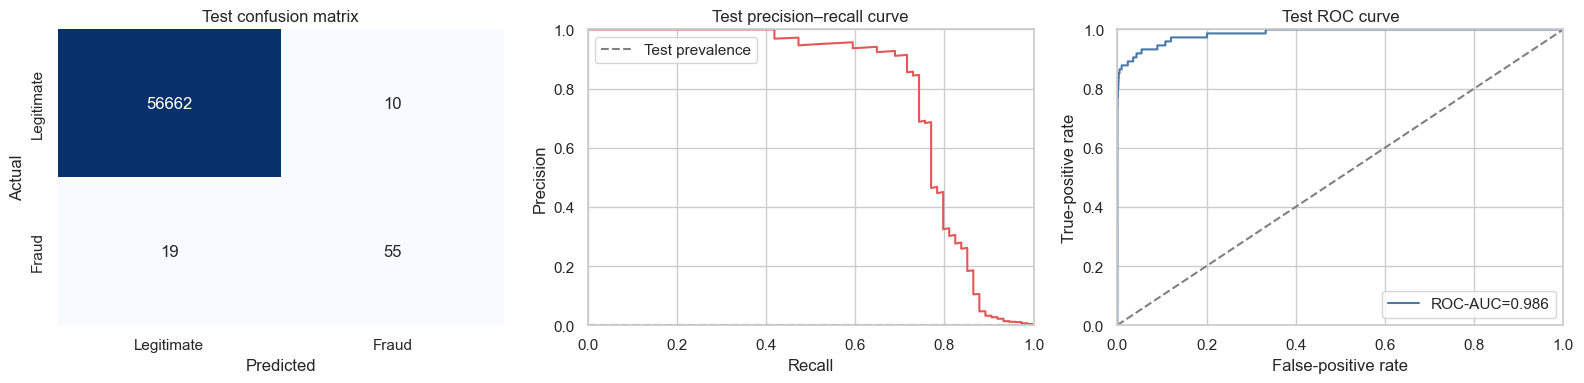

**Chart interpretation.** The confusion matrix shows 55 fraud cases caught, 19 missed, and 10 legitimate transactions flagged. The PR curve is benchmarked against the dashed test prevalence line; the ROC curve summarizes ranking over thresholds and does not imply this operating point's precision or recall. These curves use the final test labels for reporting only.

In [16]:
test_probabilities = best_model.predict_proba(splits.X_test)[:, 1]
test_result, test_matrix, test_report = test_metrics(splits.y_test, test_probabilities, selected_threshold)
test_table = pd.DataFrame([test_result])
test_table.to_csv(REPORTS_DIR / "test_evaluation.csv", index=False)
display(test_table.T.rename(columns={0: "test_value"}).round(6))
display(pd.DataFrame(test_matrix, index=["Actual legitimate", "Actual fraud"],
                     columns=["Predicted legitimate", "Predicted fraud"]))
display(pd.DataFrame(test_report).T.round(5))
tn, fp, fn, tp = test_matrix.ravel()
display(Markdown(
    f"**Test interpretation.** Test ROC-AUC is {test_result['roc_auc']:.4f}, a ranking "
    f"measure, not accuracy. Test average precision is {test_result['average_precision']:.4f} "
    f"against test fraud prevalence {test_result['fraud_prevalence']:.3%}. At the "
    f"validation-selected threshold {selected_threshold:.8f}, the model flags {tp+fp:,} "
    f"transactions: {tp:,} fraud detected, {fn:,} fraud missed, and {fp:,} false alerts. "
    f"Precision is {test_result['precision']:.3f} and recall is {test_result['recall']:.3f}; "
    "both depend on the chosen threshold. The test fraud count is limited, so these "
    "estimates have substantial sampling uncertainty."
))
fig, axes = plt.subplots(1, 3, figsize=(16, 4))
sns.heatmap(test_matrix, annot=True, fmt="d", cmap="Blues", cbar=False,
            xticklabels=["Legitimate", "Fraud"], yticklabels=["Legitimate", "Fraud"], ax=axes[0])
axes[0].set(title="Test confusion matrix", xlabel="Predicted", ylabel="Actual")
precision_curve, recall_curve, _ = precision_recall_curve(splits.y_test, test_probabilities)
axes[1].plot(recall_curve, precision_curve, color="#E45756")
axes[1].axhline(test_result["fraud_prevalence"], linestyle="--", color="gray", label="Test prevalence")
axes[1].set(title="Test precision–recall curve", xlabel="Recall", ylabel="Precision", xlim=(0, 1), ylim=(0, 1))
axes[1].legend()
fpr, tpr, _ = roc_curve(splits.y_test, test_probabilities)
axes[2].plot(fpr, tpr, color="#4C78A8", label=f"ROC-AUC={test_result['roc_auc']:.3f}")
axes[2].plot([0, 1], [0, 1], linestyle="--", color="gray")
axes[2].set(title="Test ROC curve", xlabel="False-positive rate", ylabel="True-positive rate", xlim=(0, 1), ylim=(0, 1))
axes[2].legend()
fig.tight_layout()
fig.savefig(PLOTS_DIR / "test_evaluation_curves.png", dpi=150)
plt.show()
display(Markdown(
    f"**Chart interpretation.** The confusion matrix shows {tp:,} fraud cases caught, "
    f"{fn:,} missed, and {fp:,} legitimate transactions flagged. The PR curve is "
    "benchmarked against the dashed test prevalence line; the ROC curve summarizes "
    "ranking over thresholds and does not imply this operating point's precision or "
    "recall. These curves use the final test labels for reporting only."
))

## 19. Validation-set feature importance

Permutation importance uses the selected estimator and a reproducible sample from the validation interval, scored by average precision. It measures model reliance under this sample, not causality or intrinsic feature value.

,feature,mean_ap_decrease,std_ap_decrease
14,V14,0.451510,0.014374
10,V10,0.048042,0.001136
4,V4,0.046412,0.003014
21,V21,0.004644,0.000181
3,V3,0.004387,0.001395
2,V2,0.002636,0.000803
19,V19,0.002600,0.000182
7,V7,0.001829,0.000177
1,V1,0.001342,0.001734
20,V20,0.000831,0.000317


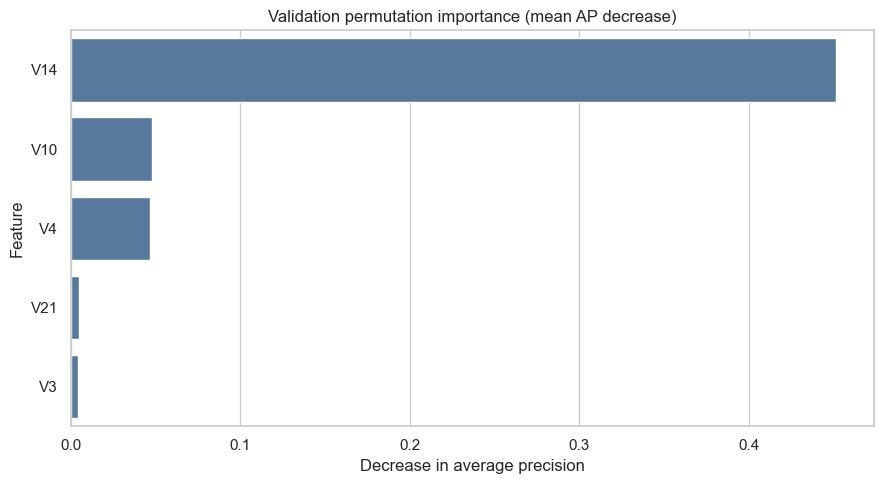

**Interpretation.** The largest mean validation AP decreases after permutation are V14 (0.45151); V10 (0.04804); V4 (0.04641); V21 (0.00464); V3 (0.00439). Values can be small or negative, and correlated features can substitute for one another. Importance depends on this model and validation sample, does not establish causation, and cannot assign real-world business meanings to anonymized PCA features.

In [17]:
importance_indices = np.arange(len(splits.y_validation))
importance = permutation_importance(
    best_model,
    splits.X_validation.iloc[importance_indices],
    splits.y_validation.iloc[importance_indices],
    scoring="average_precision",
    n_repeats=2,
    random_state=RANDOM_SEED,
    n_jobs=1,
)
importance_table = pd.DataFrame({
    "feature": FEATURE_COLUMNS,
    "mean_ap_decrease": importance.importances_mean,
    "std_ap_decrease": importance.importances_std,
}).sort_values("mean_ap_decrease", ascending=False)
display(importance_table.head(12).round(6))
importance_table.to_csv(REPORTS_DIR / "validation_permutation_importance.csv", index=False)
top_importance = importance_table.head(5)
fig, ax = plt.subplots(figsize=(9, 5))
sns.barplot(data=top_importance, y="feature", x="mean_ap_decrease", color="#4C78A8", ax=ax)
ax.set(title="Validation permutation importance (mean AP decrease)", xlabel="Decrease in average precision", ylabel="Feature")
fig.tight_layout()
fig.savefig(PLOTS_DIR / "validation_permutation_importance.png", dpi=150)
plt.show()
display(Markdown(
    "**Interpretation.** The largest mean validation AP decreases after permutation are "
    + "; ".join(f"{r.feature} ({r.mean_ap_decrease:.5f})" for r in top_importance.itertuples())
    + ". Values can be small or negative, and correlated features can substitute for "
    "one another. Importance depends on this model and validation sample, does not "
    "establish causation, and cannot assign real-world business meanings to anonymized "
    "PCA features."
))

## 20. Persist artifacts and conclude

The final pipeline contains its preprocessing and model. Its input feature names and order, software versions, model choice, random seed, and validation-selected threshold are stored alongside it. A reload check verifies that the artifact returns finite probabilities on the expected input schema.

In [18]:
pipeline_path = MODELS_DIR / "fraud_detection_pipeline.joblib"
joblib.dump(best_model, pipeline_path)
metadata = {
    "model_name": best_name,
    "model_configuration": str(best_model),
    "selected_threshold": float(selected_threshold),
    "threshold_objective": "maximum validation F2; not a business-optimal threshold",
    "feature_names_in_order": FEATURE_COLUMNS,
    "target_column": "Class",
    "target_encoding": {"0": "legitimate", "1": "fraud"},
    "training_seed": RANDOM_SEED,
    "split_strategy": "chronological 60/20/20 after exact duplicate removal",
    "duplicate_rows_removed": int(cleaning_summary["records_removed"]),
    "cleaned_fraud_count": fraud_count,
    "python_version": platform.python_version(),
    "pandas_version": pd.__version__,
    "numpy_version": np.__version__,
    "scikit_learn_version": sklearn.__version__,
    "validation_average_precision": float(comparison.loc[comparison.model == best_name, "validation_average_precision"].iloc[0]),
}
(MODELS_DIR / "model_metadata.json").write_text(json.dumps(metadata, indent=2), encoding="utf-8")
reloaded_model = joblib.load(pipeline_path)
reload_probabilities = reloaded_model.predict_proba(splits.X_test.iloc[:5])[:, 1]
assert reload_probabilities.shape == (min(5, len(splits.X_test)),)
assert np.isfinite(reload_probabilities).all() and ((reload_probabilities >= 0) & (reload_probabilities <= 1)).all()
print("Reload check passed; sample probabilities:", reload_probabilities)

top_eda = feature_effects.head(3)
top_importance_names = ", ".join(top_importance.feature.tolist())
comparison_markdown = "| Model | ROC-AUC | Average precision | Precision @ 0.5 | Recall @ 0.5 | F1 @ 0.5 |\n|---|---:|---:|---:|---:|---:|"
comparison_markdown += "\n" + "\n".join(
    f"| {row.model} | {row.validation_roc_auc:.4f} | {row.validation_average_precision:.4f} | {row.precision_at_0_5:.4f} | {row.recall_at_0_5:.4f} | {row.f1_at_0_5:.4f} |"
    for row in comparison.itertuples()
)
threshold_markdown = "| Threshold | Precision | Recall | F2 | TP | FP | FN | Alerts |\n|---:|---:|---:|---:|---:|---:|---:|---:|"
threshold_markdown += "\n" + "\n".join(
    f"| {row.threshold:.6g} | {row.precision:.3f} | {row.recall:.3f} | {row.f2:.3f} | {row.true_positives} | {row.false_positives} | {row.false_negatives} | {row.alert_volume} |"
    for row in threshold_table.itertuples()
)
summary_text = f'''# Final project summary\n\n- Dataset: {len(raw):,} raw rows, {raw.shape[1]} columns; {raw_fraud_count:,} raw fraud labels ({raw_fraud_count/len(raw):.4%}); after duplicate removal {fraud_count:,} ({fraud_rate:.4%}).\n- Cleaning: removed {cleaning_summary['records_removed']:,} exact duplicate rows ({raw_fraud_count-fraud_count} fraud, {cleaning_summary['records_removed']-(raw_fraud_count-fraud_count)} legitimate); no missing values imputed; no non-duplicate outliers removed; raw CSV preserved.\n- Chronological split after cleaning: train {len(splits.y_train):,} rows / {int(splits.y_train.sum())} fraud; validation {len(splits.y_validation):,} / {int(splits.y_validation.sum())}; test {len(splits.y_test):,} / {int(splits.y_test.sum())}.\n- Selected model: {best_name}; validation average precision {comparison.loc[comparison.model == best_name, 'validation_average_precision'].iloc[0]:.5f}.\n- Final test: ROC-AUC {test_result['roc_auc']:.4f}; average precision {test_result['average_precision']:.4f}; precision {test_result['precision']:.4f}; recall {test_result['recall']:.4f}; F1 {test_result['f1']:.4f}; specificity {test_result['specificity']:.4f}.\n- Validation-selected threshold: {selected_threshold:.8f} (F2 objective; not cost- or capacity-optimized). Test confusion: TN={tn:,}, FP={fp:,}, FN={fn:,}, TP={tp:,}.\n- Leading validation permutation-importance features: {top_importance_names}. These are model/sample-dependent signals, not causal explanations.\n- EDA: fraud amount median {fraud['median']:.2f} vs legitimate median {leg['median']:.2f}; top three standardized PCA-feature differences: {', '.join(f'{r.feature} ({r.standardized_mean_difference:.2f})' for r in top_eda.itertuples())}.\n\n## Limitations\n\nThis is a historical benchmark with anonymized PCA features, sparse fraud cases, no documented calendar reference for Time, and no source/license documentation included alongside the local CSV. Chronological holdout results may be unstable and do not establish present-day banking effectiveness, calibrated operational risk, or business value. Threshold selection optimizes validation F2 in the absence of costs or investigation capacity.\n\n## Interview-style critical review\n\n1. **Temporal representativeness:** one chronological split is vulnerable to drift and small numbers of later fraud cases. Improve with repeated rolling-origin evaluation and uncertainty intervals.\n2. **Decision economics:** F2 is only a proxy without costs or analyst capacity. Obtain validated cost and capacity assumptions, then compare expected utility and precision-at-capacity.\n3. **Dataset validity and reproducibility:** local provenance/license and the reason for repeated records are not documented. Verify source terms and definitions, and validate on more recent, independently sampled data before operational claims.\n'''
summary_path = REPORTS_DIR / "final_summary.md"
summary_path.write_text(summary_text, encoding="utf-8")
readme_text = f'''# Credit Card Fraud Detection\n\nReproducible analysis of the locally provided ULB / Worldline credit-card-fraud benchmark. The notebook is the primary deliverable; results are computed from the local dataset when it runs.\n\n## Problem and dataset\n\nThe binary target is `Class` (1 fraud, 0 legitimate). The standard file contains `Time`, `V1`–`V28`, `Amount`, and `Class`. The commonly documented reference is [MLG-ULB Credit Card Fraud Detection on Kaggle](https://www.kaggle.com/datasets/mlg-ulb/creditcardfraud). No source documentation or license accompanied the CSV, so provenance and redistribution permission cannot be verified. Do not commit or redistribute the dataset unless its terms permit it. `Time` is elapsed seconds, not a known wall-clock time. `V1`–`V28` are anonymized transformed values.\n\n## Observed results\n\n- Raw data: {len(raw):,} rows, {raw.shape[1]} columns; fraud prevalence {raw_fraud_count:,}/{len(raw):,} ({raw_fraud_count/len(raw):.4%}); cleaned fraud count {fraud_count:,} ({fraud_rate:.4%}).\n- Cleaning: {cleaning_summary['records_removed']:,} exact duplicate records removed from the analysis copy ({raw_fraud_count-fraud_count} fraud, {cleaning_summary['records_removed']-(raw_fraud_count-fraud_count)} legitimate); no missing or non-finite values, and no non-duplicate outliers removed. The original CSV remains untouched.\n- EDA: fraud amount median {fraud['median']:.2f}, legitimate amount median {leg['median']:.2f}; largest absolute standardized mean differences among PCA variables: {', '.join(f'{r.feature} ({r.standardized_mean_difference:.2f})' for r in top_eda.itertuples())}. Descriptive only; PCA features have no assigned business meaning.\n- Chronological splits: train {len(splits.y_train):,} rows/{int(splits.y_train.sum())} fraud; validation {len(splits.y_validation):,}/{int(splits.y_validation.sum())}; test {len(splits.y_test):,}/{int(splits.y_test.sum())}.\n- Best validation model by average precision: **{best_name}** (AP {comparison.loc[comparison.model == best_name, 'validation_average_precision'].iloc[0]:.5f}).\n\n### Validation model comparison\n\n{comparison_markdown}\n\n### Validation threshold trade-offs\n\n{threshold_markdown}\n\n- Final test: ROC-AUC {test_result['roc_auc']:.4f}; AP {test_result['average_precision']:.4f}; precision {test_result['precision']:.4f}; recall {test_result['recall']:.4f}; F1 {test_result['f1']:.4f}; threshold {selected_threshold:.8f}; TN={tn}, FP={fp}, FN={fn}, TP={tp}. Threshold selected on validation by F2, not on test and not by business costs.\n\nResults are benchmark estimates with a small number of fraud examples in the chronological holdout; they do not prove live banking effectiveness. See [the final summary](reports/final_summary.md) for limitations and a critical review.\n\n## Setup and execution\n\n1. Use Python 3.10 or newer.\n2. Install dependencies: `python -m pip install -r requirements.txt`.\n3. Place the downloaded `creditcard.csv` at the project root (or update `DATA_PATH` in the notebook).\n4. Run from the project root: `jupyter nbconvert --to notebook --execute --inplace notebooks/credit_card_fraud_detection.ipynb`. For interactive use: `jupyter lab notebooks/credit_card_fraud_detection.ipynb`.\n\n## Project structure\n\n- `notebooks/credit_card_fraud_detection.ipynb` — end-to-end executed analysis.\n- `src/data_validation.py`, `src/data_cleaning.py`, `src/eda.py`, `src/train.py`, `src/evaluate.py` — reusable workflow modules.\n- `reports/` — quality audit, model comparison, test metrics, permutation importance, and summary.\n- `plots/` — generated EDA and evaluation figures.\n- `models/` — fitted pipeline and JSON metadata including schema and decision threshold.\n- `data/raw/` — reserved for data only if safely copied; this project leaves the input CSV in place to avoid duplication.\n\n## Cleaning and modeling decisions\n\nExact duplicates are removed while keeping the first occurrence before splitting; no target changes, imputation, or automatic outlier deletion are made. A chronological 60/20/20 split is used without stratification. Logistic Regression scales within its training pipeline; tree models use unscaled inputs. Class weights/sample weights address imbalance in selected models. Model choice and the F2 decision threshold use validation only; the test interval is reserved for final reporting.\n\n## Dependencies and future work\n\nSee `requirements.txt`. Improve the evidence with rolling-origin validation, uncertainty intervals, verified current data with documented provenance, probability-calibration checks on separate data, and threshold optimization using actual review capacity and error costs. This benchmark alone is not sufficient for production decisions.\n'''
(PROJECT_ROOT / "README.md").write_text(readme_text, encoding="utf-8")
print("Saved model, metadata, reports, and README.")
display(Markdown(summary_text))

Reload check passed; sample probabilities: [0.00801063 0.00507957 0.00698301 0.01395319 0.0053566 ]
Saved model, metadata, reports, and README.


# Final project summary

- Dataset: 284,807 raw rows, 31 columns; 492 raw fraud labels (0.1727%); after duplicate removal 473 (0.1667%).
- Cleaning: removed 1,081 exact duplicate rows (19 fraud, 1062 legitimate); no missing values imputed; no non-duplicate outliers removed; raw CSV preserved.
- Chronological split after cleaning: train 170,235 rows / 342 fraud; validation 56,745 / 57; test 56,746 / 74.
- Selected model: HistGradientBoosting; validation average precision 0.77432.
- Final test: ROC-AUC 0.9860; average precision 0.7764; precision 0.8462; recall 0.7432; F1 0.7914; specificity 0.9998.
- Validation-selected threshold: 0.90566246 (F2 objective; not cost- or capacity-optimized). Test confusion: TN=56,662, FP=10, FN=19, TP=55.
- Leading validation permutation-importance features: V14, V10, V4, V21, V3. These are model/sample-dependent signals, not causal explanations.
- EDA: fraud amount median 9.82 vs legitimate median 22.00; top three standardized PCA-feature differences: V17 (-8.09), V14 (-7.52), V12 (-6.35).

## Limitations

This is a historical benchmark with anonymized PCA features, sparse fraud cases, no documented calendar reference for Time, and no source/license documentation included alongside the local CSV. Chronological holdout results may be unstable and do not establish present-day banking effectiveness, calibrated operational risk, or business value. Threshold selection optimizes validation F2 in the absence of costs or investigation capacity.

## Interview-style critical review

1. **Temporal representativeness:** one chronological split is vulnerable to drift and small numbers of later fraud cases. Improve with repeated rolling-origin evaluation and uncertainty intervals.
2. **Decision economics:** F2 is only a proxy without costs or analyst capacity. Obtain validated cost and capacity assumptions, then compare expected utility and precision-at-capacity.
3. **Dataset validity and reproducibility:** local provenance/license and the reason for repeated records are not documented. Verify source terms and definitions, and validate on more recent, independently sampled data before operational claims.
